# Lab: Classes and Inheritance with Regression

In this lab, we will be using classes to organize code for fitting regression models.

## Getting started

First, let's create some data to work with. The code below uses a constant, cosine, and sine function with coefficients of $c_0 = -1$, $c_1 = 2$, and $c_2 = 1$. We use 20 points between $-\pi$ and $\pi$ and add a little random noise to make the data more realistic.

$$ y_i = -1 + 2 \cos(x_i) +  \sin(x_i) + \epsilon_i,\qquad i=1,\dots,n$$

where $\epsilon_i$ indicates a value of small random noise. We can also write this as:

$$ y_i = -1 \times 1 + 2 \times \cos(x_i) + 1\times \sin(x_i) + \epsilon_i,\qquad i=1,\dots,n$$

This makes it clear we are writing the $y_i$'s as (approximately) a linear combination of functions of the $x_i$ where 

- $c_0 = -1,\quad\  f_0(x) = 1$
- $c_1 = 2,\qquad f_1(x) = \cos(x)$
- $c_2 = 1,\qquad f_2(x) = \sin(x)$

Later, when we fit the data, we should get coefficients close to our original values, but they may not be exactly the same because of the noise.

Run the cell below and look at how `x_vals` and `y_vals` are created.


In [2]:
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

# Define the three functions f_0, f_1, f_2
def f_0(x):
    return 1.0

def f_1(x):
    return np.cos(x)

def f_2(x):
    return np.sin(x)

# Define coefficients
c_0, c_1, c_2 = -1, 2, 1

# Generate evenly spaced points between -pi and pi
x_vals = np.linspace(-np.pi, np.pi, 20)

# Evaluate the linear combination of functions...
y_vals = c_0*f_0(x_vals) + c_1*f_1(x_vals) + c_2*f_2(x_vals)

# ... and then add some random noise
rng = np.random.default_rng(12)
noise = 1e-1 * rng.standard_normal(y_vals.shape)
y_vals = y_vals + noise

In [ ]:

print(y_vals)

[-1.         -0.94581724 -0.78914051 -0.54694816 -0.24548549  0.08257935
  0.40169542  0.67728157  0.87947375  0.9863613   0.9863613   0.87947375
  0.67728157  0.40169542  0.08257935 -0.24548549 -0.54694816 -0.78914051
 -0.94581724 -1.        ]
[-3.00068268 -3.11171962 -3.11833489 -2.85866714 -2.29849362 -1.95198162
 -1.17507802 -0.51322709  0.27222486  0.90800438  1.13512241  1.2844829
  0.89921019  0.73387059  0.07104886 -0.34403177 -1.16804493 -1.86913336
 -2.57272051 -2.93871377]


## Fitting the data

Next, we'll use a matrix called `A` to estimate our coefficients. Each row represents a data point $x_i$, and each column contains the values from one of our functions. Column 0 uses `f_0`, column 1 uses `f_1`, and column 2 uses `f_2`.

Here's what the matrix looks like:

$$A = \begin{bmatrix} 1 & \cos(x_1) & \sin(x_1)\\[2pt]
1 & \cos(x_2) & \sin(x_2)\\[2pt]
1 & \cos(x_3) & \sin(x_3)\\[2pt]
\vdots & \vdots & \vdots \\[2pt]
1 & \cos(x_n) & \sin(x_n)
 \end{bmatrix}$$

We'll use `numpy.linalg` to calculate the optimal coefficients, so you don't need to worry too much about the linear algebra right now. We'll come back to these steps when we create the `fit` method for our class.

Run the cell below and compare the estimated coefficients $\hat{c}_0$, $\hat{c}_1$, and $\hat{c}_2$ to our original values of -1, 2, and 1.

In addition, we'll compute the values $\hat{y}_i$, which are the prediction of our model, given the data $x_i$. To quantify the accuracy of the model, we'll also compute the sum of squared error between the data $y_i$ and the estimates $\hat{y}_i$:

$$ \sum_{i=1}^n(\hat{y}_i - y_i)^2$$


In [8]:
# Form the matrix A
A = np.zeros((len(x_vals), 3))
A[:, 0] = f_0(x_vals)
A[:, 1] = f_1(x_vals)
A[:, 2] = f_2(x_vals)

# Set up and solve the linear system for the estimate coefficients
normal_matrix = A.T @ A
rhs = A.T @ y_vals
c_estimate = la.solve(normal_matrix, rhs)

# Extract estimated coefficients
c_0_est = c_estimate[0]
c_1_est = c_estimate[1]
c_2_est = c_estimate[2]

print("Estimated coefficients:")
print(" c_0:", c_0_est)
print(" c_1:", c_1_est)
print(" c_2:", c_2_est)

# Compute the prediction of our model
y_estimate = c_0_est*f_0(x_vals) + c_1_est*f_1(x_vals) + c_2_est*f_2(x_vals)

# Compute and print the sum of squared errors
print("Squared error:", np.sum((y_estimate - y_vals)**2))

Estimated coefficients:
 c_0: -0.983546020551319
 c_1: 1.9459444179604872
 c_2: 1.0078830675729031
Squared error: 0.1550251517725127


Let's plot the original data alongside the fitted function. The scattered points are the noisy observations, while the line shows the model's estimate between those points.

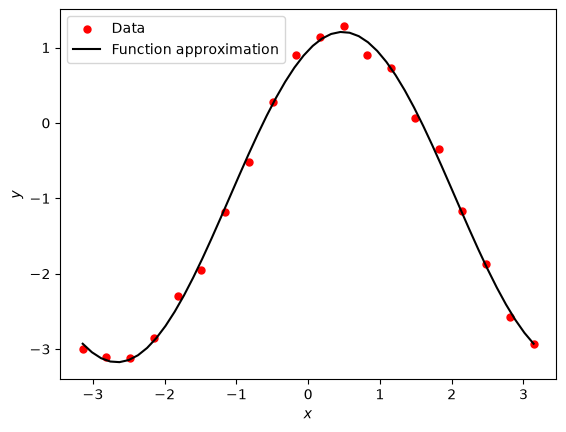

In [9]:
# Generate more points for plotting
x_plot = np.linspace(-np.pi, np.pi, 50)

# Evaluate our model at these points:
y_plot = c_estimate[0]*f_0(x_plot) + c_estimate[1]*f_1(x_plot) + c_estimate[2]*f_2(x_plot)

# Plot it
plt.scatter(x_vals, y_vals, s=25, color='red', label='Data')
plt.plot(x_plot, y_plot, color='black', label='Function approximation')
plt.legend()
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.show()

Once we have the coefficients, we can also estimate `y` for inputs that weren't part of the original dataset. Here are examples with one new `x` value and with several values at once.

In [10]:
x_new = 2*np.pi
y_pred = c_estimate[0]*f_0(x_new) + c_estimate[1]*f_1(x_new) + c_estimate[2]*f_2(x_new)
print("New observation x:", x_new)
print("Single prediction y:", y_pred)
print()

x_new = np.array([5*np.pi/4, 3*np.pi/2, 2*np.pi, 9*np.pi/4])
y_pred = c_estimate[0]*f_0(x_new) + c_estimate[1]*f_1(x_new) + c_estimate[2]*f_2(x_new)
print("New observations x_i:", x_new)
print("Multiple predictions y_i:", y_pred)

New observation x: 6.283185307179586
Single prediction y: 0.962398397409168

New observations x_i: [3.92699082 4.71238898 6.28318531 7.06858347]
Multiple predictions y_i: [-3.07221747 -1.99142909  0.9623984   1.10512542]


## Putting the regression code into a class

So far, we've been doing all of our calculations directly in notebook cells. This works for a single example, but if we wanted to use a different dataset, we'd have to repeat a lot of the same code. To make things easier, we'll organize the calculations into a class.

Complete the three methods below using the TODO comments as a guide. You can look back at Section 2 if you need help with the calculations.


- `__init__` should save the supplied list of functions as `self.f_list`. Set `self.coefficients`, `self.x`, and `self.y` to `None` for now.
- `fit` should save the values of `x` and `y` to corresponding attributes, create the matrix `A`, and fill each column using the corresponding function in `self.f_list`. Then calculate `A.T @ A` and `A.T @ y`, solve the system, and store the result in `self.coefficients`.
- `predict` should return the sum of each function's value multiplied by its fitted coefficient. For this exercise, you can assume `x` is a NumPy array.

`fit` doesn't need to *return* the coefficients. It stores them in the object so `predict` can use them later.

In [ ]:
class OrdinaryLeastSquares:
    def __init__(self, function_list):
        
        self.f_list = function_list
        self.coefficients = None
        self.x = None
        self.y = None

    def fit(self, x, y):
        
        self.x = x
        self.y = y
        A = np.zeros((len(x), len(self.f_list)))

        # Fill in columns of matrix
        for k in range(len(self.f_list)):
            A[:, k] = self.f_list[k](x)

        # Set up linear system for coefficients
        normal_matrix = A.T @ A
        rhs = A.T @ y

        # Solve for the coefficients and store them in self.coefficients.
        c_estimate = la.solve(normal_matrix, rhs)
        self.coefficients = c_estimate

    def predict(self, x):
        y_pred = np.zeros(x.shape)
        
        
        # TODO: Use the functions and stored
        #       coefficients to calculate y_pred, given the input x
        y_estimate = c_0_est*f_0(x_vals) + c_1_est*f_1(x_vals) + c_2_est*f_2(x_vals)
        

        c_0_est = c_estimate[0]
        c_1_est = c_estimate[1]
        c_2_est = c_estimate[2]
        
        return y_pred

### Trying it out

Now, let's test our model using the same three functions from earlier in the lab. The code below fits the model to our data, prints the coefficients, and plots the predictions.

If you've completed the class correctly, your graph should look similar to the one from Section 2.


In [ ]:
trig_regression = OrdinaryLeastSquares([f_0, f_1, f_2])
trig_regression.fit(x_vals, y_vals)
print("Class coefficients:", trig_regression.coefficients)

x_plot = np.linspace(-np.pi, np.pi, 50)
y_plot = trig_regression.predict(x_plot)
plt.scatter(x_vals, y_vals, s=25, color='red', label='Data')
plt.plot(x_plot, y_plot, color='black', label='Class prediction')
plt.legend()
plt.show()

### Fitting a Quadratic Function

We can also use OrdinaryLeastSquares to fit a quadratic function of the form:

$$y = a + bx + cx^2$$

For this model, the matrix (A) has three columns: the constant $1$, the values of $x_i$, and the values of $x_i^2$:
$$A = \begin{bmatrix} 1 & x_1 & x_1^2\\[2pt]
1 & x_2 & x_2^2\\[2pt]
1 & x_3 & x_3^2\\[2pt]
\vdots & \vdots & \vdots \\[2pt]
1 & x_n & x_n^2
 \end{bmatrix}$$

 Using the data below, define the three functions that correspond to the columns of (A). Then create an `OrdinaryLeastSquares` object, fit the data, and print the coefficients.

You can refer to the earlier example if you need help.

**Hint:** The names $a$, $b$, and $c$ for the coefficients are arbitrary. You could rename them $c_0$, $c_1$, and $c_2$ to make the connection from the first example more clear.

In [ ]:
x_quad = np.array([-3, -2, -1, 0, 1, 2, 3])
y_quad = np.array([8.2, 3.1, 0.4, -1.0, -1.6, -0.9, 1.2])

# TODO: Define the three functions for a + bx + cx^2


# TODO: Create an OrdinaryLeastSquares object


# TODO: Fit the model to the data


# TODO: Print the coefficients

## A simpler model using inheritance

Next, we'll use inheritance to create a simple linear regression model. Since simple linear regression fits a straight line, we only need two functions: a constant for the intercept and $f(x) = x$ for the slope.

We've already written the code for fitting coefficients and making predictions in `OrdinaryLeastSquares`, so there's no need to write those methods again. Instead, we'll create `SimpleLinearRegression` as a subclass, which allows us to use the `fit` and `predict` methods from the original class.

In the initializer, we'll store the two functions in `self.f_list` and initialize the attributes needed for our model. We've provided the two functions below, so you'll just need to complete the remaining parts of the initializer.

We'll also add a method called `compute_r_squared` to calculate the R-squared coefficient, which tells us how well the line fits the data. Use the equations below to complete the method, store the result in `self.r_squared`, and return it.

The formula for the R-squared coefficient is as follows:

$$ \bar{x} = \frac{1}{n}\sum_{i=1}^n x_i,\qquad\textrm{(the mean of $\boldsymbol{x}$)}$$
$$ \bar{y} = \frac{1}{n}\sum_{i=1}^n x_i,\qquad\textrm{(the mean of $\boldsymbol{y}$)}$$
$$s_{xx} = \sum_{i=1}^n(x_i - \bar{x})^2$$
$$s_{yy} = \sum_{i=1}^n(y_i - \bar{y})^2$$
$$s_{xy} = \sum_{i=1}^n(x_i - \bar{x})(y_i - \bar{y})$$
$$r^2 = \frac{s_{xy}^2}{s_{xx}s_{yy}},\qquad\textrm{(the R-squared coefficient)}$$

**Hint:** Use built-in NumPy functions instead of loops.

In [ ]:
class SimpleLinearRegression(OrdinaryLeastSquares):
    def __init__(self):
        # TODO: Initialize self.coefficients,
        #       self.intercept, and self.slope to None.

        f_0 = lambda x: 1.0
        f_1 = lambda x: x

        # TODO: Store f_0 and f_1 in self.f_list.

        # TODO: Initialize self.r_squared to None.


    def compute_r_squared(self):
        if self.r_squared is None:
            x_bar = np.mean(self.x)
            y_bar = np.mean(self.y)

            s_xy = np.sum((self.x - x_bar)*(self.y - y_bar))

            # TODO: Compute s_xx and s_yy

            # TODO: Calculate R-squared using
            #   s_xx, s_xy, and s_yy.
            #   Store the result in self.r_squared.

        return self.r_squared

### Trying the subclass
Now, let's use the three points below to fit a straight line. Run the cell to print the coefficients and R-squared value, then plot the line alongside the data. Remember, the first coefficient is the intercept and the second is the slope.

Notice that we can use `fit` and `predict` with `SimpleLinearRegression` even though we didn't define them in the subclass. That's because it inherits those methods from `OrdinaryLeastSquares`.


In [ ]:
linear_x = np.array([1, 2, 3])
linear_y = np.array([0, 3, 2])

L = SimpleLinearRegression()
L.fit(linear_x, linear_y)
print("Intercept and slope:", L.coefficients)
print("R-squared:", L.compute_r_squared())

x_line = np.linspace(1, 3, 50)
plt.scatter(linear_x, linear_y, label="Data")
plt.plot(x_line, L.predict(x_line), label="Fitted line")
plt.legend(loc='lower right')
plt.show()

In [ ]:
lab_skills = np.array([4.5, 5.5, 6.5, 7.5, 8.5, 9.5])
optimal_floor = np.array([4.25, 4.25, 4.75, 5.5, 6.75, 7])


L = SimpleLinearRegression()
L.fit(lab_skills, optimal_floor)
print("Intercept and slope:", L.coefficients)
print("R-squared:", L.compute_r_squared())

x_line = np.linspace(4, 10, 50)
plt.scatter(lab_skills, optimal_floor, label="Data")
plt.plot(x_line, L.predict(x_line), label="Fitted line")
plt.legend(loc="best")
plt.show()